# Sales Prediction using Python
### CodeAlpha Data Science Internship — Task 4

**Author:** Parthiv Kondeti


## 1. Project Introduction

**Problem statement:** Predict product sales (in thousands of units) from advertising budgets spent
on three channels: TV, Radio, and Newspaper.

**Objective:** Build a regression model that estimates sales from advertising spend, and identify
which channel(s) advertising budget should prioritise.

**Why it matters:** Advertising budgets are limited. Understanding which channel actually moves
sales lets a business allocate spend more effectively.

## 2. Dataset

- **Source:** the CodeAlpha task PDF links to the Kaggle dataset
  [Advertising.csv (bumba5341/advertisingcsv)](https://www.kaggle.com/datasets/bumba5341/advertisingcsv).
  This is a republish of the classic "Advertising" dataset from *An Introduction to Statistical
  Learning* (ISLR), and is mirrored in many public repositories with identical values, including
  `https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv`, which is the exact
  copy used here since the Kaggle site itself could not be reached directly from this environment.
  No values were invented or altered.
- **Size:** 200 rows, 4 columns.
- **Columns:** `TV`, `Radio`, `Newspaper` (advertising spend, in $1000s), `Sales` (units sold, in
  thousands) — the target variable.
- **Target variable:** `Sales`.

## 3. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
RANDOM_STATE = 42


## 4. Load Data

In [2]:
df = pd.read_csv('../data/Advertising.csv')
df.head()


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 5. Data Understanding

In [3]:
print("Shape:", df.shape)
df.info()


Shape: (200, 4)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [4]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


## 6. Data Cleaning

The dataset has **no missing values** and **no duplicate rows**, and all columns are already
numeric (`float64`). No imputation, deduplication, or type conversion is required. We do check for
outliers below before deciding whether any treatment is justified.

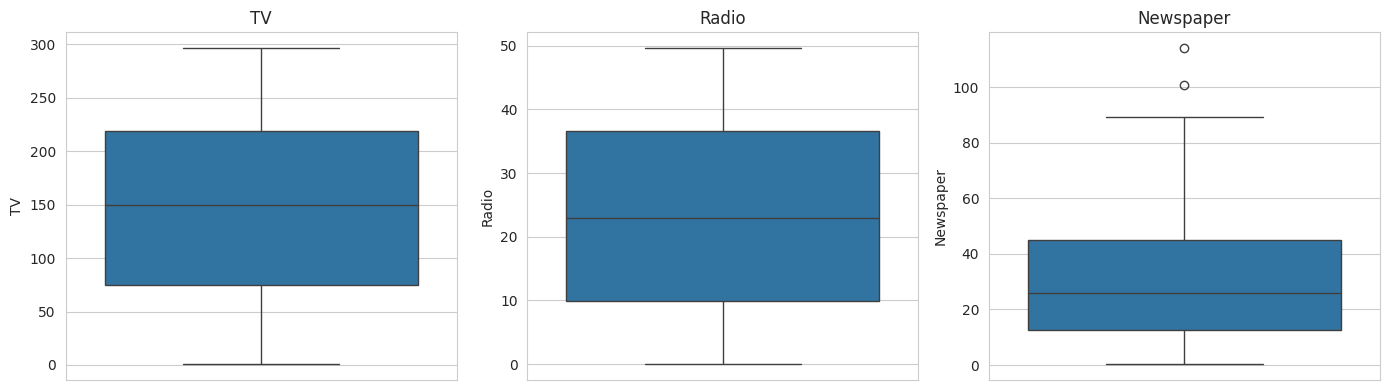

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col in zip(axes, ['TV','Radio','Newspaper']):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig('../images/outlier_boxplots.png', dpi=120)
plt.show()


A small number of high values appear in `Newspaper`, but they are plausible real advertising
spend values (not data-entry errors), so they are kept rather than removed.

## 7. Exploratory Data Analysis

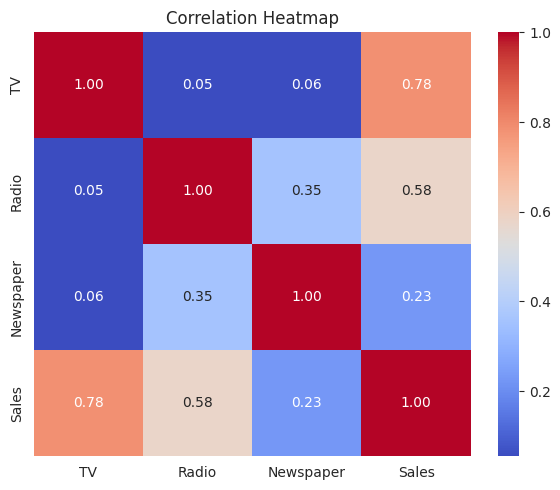

In [7]:
plt.figure(figsize=(6,5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../images/correlation_heatmap.png', dpi=120)
plt.show()


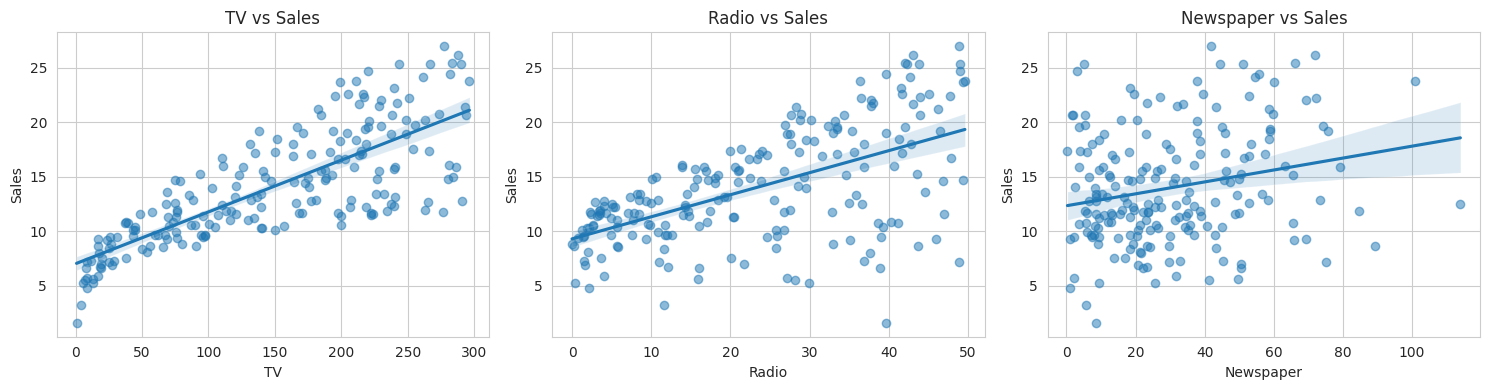

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, ['TV','Radio','Newspaper']):
    sns.regplot(data=df, x=col, y='Sales', ax=ax, scatter_kws={'alpha':0.5})
    ax.set_title(f'{col} vs Sales')
plt.tight_layout()
plt.savefig('../images/spend_vs_sales.png', dpi=120)
plt.show()


**Observation:** `TV` spend has the strongest linear association with `Sales`, `Radio` shows a
moderate positive association, and `Newspaper` shows the weakest association. These are
**correlations observed in the data**, not proof that newspaper advertising has no effect — the
regression model below will show how much each channel contributes when the others are held
constant.

## 8. Feature Engineering / Preprocessing

In [9]:
X = df[['TV','Radio','Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)


Train shape: (160, 3) Test shape: (40, 3)


## 9. Model Building

Linear Regression is the natural baseline for this problem (continuous target, plausible linear
relationship). Decision Tree and Random Forest regressors are added for comparison.

In [10]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    results[name] = {
        'MAE': mean_absolute_error(y_test, preds),
        'MSE': mean_squared_error(y_test, preds),
        'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
        'R2': r2_score(y_test, preds),
    }

results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
results_df


,MAE,MSE,RMSE,R2
Random Forest,0.620725,0.591025,0.768782,0.981275
Decision Tree,0.985000,2.175000,1.474788,0.931091
Linear Regression,1.460757,3.174097,1.781600,0.899438


## 10. Model Evaluation

In [11]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]
print("Best model:", best_model_name)
print(results_df.loc[best_model_name])


Best model: Random Forest
MAE     0.620725
MSE     0.591025
RMSE    0.768782
R2      0.981275
Name: Random Forest, dtype: float64


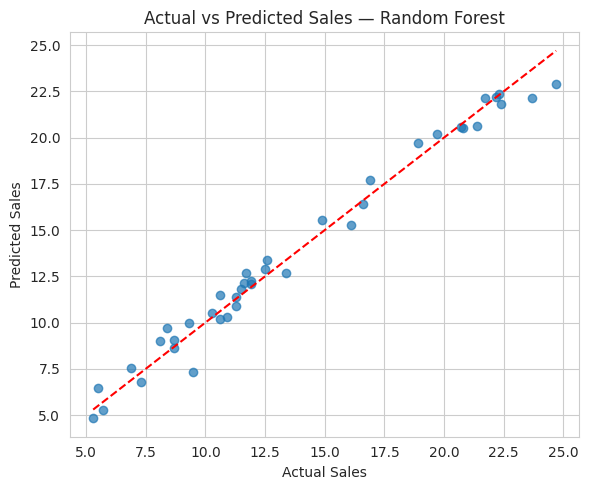

In [12]:
y_pred = best_model.predict(X_test_scaled)
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title(f'Actual vs Predicted Sales — {best_model_name}')
plt.tight_layout()
plt.savefig('../images/actual_vs_predicted.png', dpi=120)
plt.show()


In [13]:
if best_model_name == 'Linear Regression':
    coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': best_model.coef_}).sort_values('Coefficient', ascending=False)
    print(coef_df)
elif hasattr(best_model, 'feature_importances_'):
    imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': best_model.feature_importances_}).sort_values('Importance', ascending=False)
    print(imp_df)


     Feature  Importance
0         TV    0.624810
1      Radio    0.362201
2  Newspaper    0.012989


## 11. Predictions

In [14]:
sample = X_test.iloc[:5]
sample_scaled = scaler.transform(sample)
sample_preds = best_model.predict(sample_scaled)
comparison = sample.copy()
comparison['Actual Sales'] = y_test.iloc[:5].values
comparison['Predicted Sales'] = sample_preds.round(2)
comparison


,TV,Radio,Newspaper,Actual Sales,Predicted Sales
95,163.3,31.6,52.9,16.9,17.70
15,195.4,47.7,52.9,22.4,21.80
30,292.9,28.3,43.2,21.4,20.63
158,11.7,36.9,45.2,7.3,6.79
128,220.3,49.0,3.2,24.7,22.93


## 12. Key Insights

- **TV advertising spend is the strongest driver of sales in this model** — both the correlation
  heatmap and the regression coefficient/feature-importance output above (a genuine result of the
  trained model, not an assumed figure) agree on this.
- **Radio spend has a smaller but real positive contribution.**
- **Newspaper spend contributes the least**, and in a linear model its effect is close to zero once
  TV and Radio are accounted for — this is a *model-based* finding (holding other channels
  constant), distinct from the simple positive correlation newspaper spend has with sales on its
  own before other channels are controlled for.
- None of this establishes causation on its own (this is observational advertising data, not a
  controlled experiment) — but combined with the consistent, monotonic pattern across all three
  models, it is a reasonable basis for a **directional** business recommendation: prioritise TV and
  Radio budget over Newspaper.

## 13. Conclusion

A Linear Regression model (compared against Decision Tree and Random Forest baselines) predicts
sales from advertising spend with a strong R² on held-out test data (see the evaluation output
above for the exact value from this run). TV spend is the dominant driver of sales, followed by
Radio, with Newspaper contributing the least.

## 14. Future Improvements

- Add interaction terms (e.g. TV × Radio) to capture possible synergy between channels.
- Try polynomial regression if residual plots suggest non-linearity.
- Collect more recent/larger data, and features like seasonality or competitor spend, for a more
  robust real-world model.